# Stack temperature against the gas-line heaters: ERH, EAGH, EAOH1, EAOH2, EAOH3

Same day files as `operating_states.ipynb`, labelled with the **8 decided plant stages** (`operating_states.ipynb` §12), one figure per stretch of consecutive days as in §9.4b, but showing
only the **stack temperature compared with the five gas-line heaters**:

| Heater | What it heats |
|---|---|
| **ERH** | reformer / burner housing |
| **EAGH** | reformate line, reformer → stack anode |
| **EAOH1, EAOH2** | anode off-gas, the two branches to the afterburner (TOX) |
| **EAOH3** | anode off-gas recycle line, stack anode outlet → ejector |

* **Stages:** Heat-up air · Heat-up N₂+H₂ · Hot standby · Fuel switch · Part load · Air-flow cooling · Shutdown · Trip: purge,
  from `scripts/plant_stages.py` (built on `ops.segment()` and the trip windows of `industrial_stages.py`; nothing there changes).
  The heater signals are joined on per minute.
* The helper code lives in `scripts/heater_temps.py`; outputs go to `heater_temperatures/`.
* Stack T is the median of the healthy `TIR_4_6_*` module thermocouples, the same signal the stage is decided on.

In [1]:
import contextlib
import io
import sys

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, "scripts")  # helper modules live in 03_data_analysis/scripts/
import heater_temps as ht
import operating_states as ops
import plant_stages as ps

pd.set_option("display.max_rows", 120)
pd.set_option("display.width", 220)

## 1. Heater sensors

Sources: `../01_docs/component_sensor_map_en.md` §1.5 (ERH, EAGH), §1.6 (EAOH1–3), §4 (trip values).

* **Control thermocouple `TIRC_*`** is drawn in the plots. The **safety thermocouple `TIRZ_8_2_*`** sits on the same
  heater: over all 39 days it differs from the control TC by a median of 1–11 K (EAOH3: 16 K) with correlation ≥ 0.98, so it
  is used only for the trip margins in section 5.
* **Current `pi_IIR_*_ActVal`** (0–16 A). The `PLC_pv_rCurr*` heater columns read 0 on all 39 days and are not used.
  A heater counts as **on** above 0.5 A; the off state reads 0.0–0.1 A.
* The probes next to the heaters (reformer outlet `TIRC_3_17`, stack anode outlet `TIRC_5_2_1/2`, recycle inlet
  `TIR_6_01`) are loaded as well (`T_reformer_out_C`, `T_anode_out_C`, `T_recycle_in_C`) but not plotted.

In [2]:
pd.DataFrame(
    {
        n: {
            "where": h["where"],
            "control TC": h["temp"],
            "safety TC": h["safety"],
            "current": h["current"],
            "trip above °C": h["trip"],
            "rated kW": h["rated_kW"],
        }
        for n, h in ht.HEATERS.items()
    }
).T

,where,control TC,safety TC,current,trip above °C,rated kW
ERH,reformer / burner housing heater,TIRC_5_17,TIRZ_8_2_5,pi_IIR_5_1_3_ActVal,860,3.3
EAGH,reformate line heater (reformer → stack anode),TIRC_3_1_1,TIRZ_8_2_1,pi_IIR_3_1_1_ActVal,950,1.3
EAOH1,"anode off-gas heater, TOX branch 1",TIRC_5_3_1,TIRZ_8_2_2,pi_IIR_5_1_1_ActVal,950,1.3
EAOH2,"anode off-gas heater, TOX branch 2",TIRC_5_3_2,TIRZ_8_2_3,pi_IIR_5_1_2_ActVal,950,1.3
EAOH3,anode off-gas recycle heater (→ ejector),TIRC_6_1_1,TIRZ_8_2_4,pi_IIR_6_1_1_ActVal,950,1.3


## 2. Plant stages for all day files, heater signals joined

`ops.segment_all()` labels every minute of every day file as in `operating_states.ipynb`; `ht.plant_days()` then applies
`plant_stages.label()` to all days at once (trip windows can cross midnight). Column `stage` is now the **plant stage**;
the old operating_states stage is kept as `old_stage`.
`ht.heater_states()` adds per heater: temperature `T_<heater>_C`, safety TC `Tsafe_<heater>_C`, current `I_<heater>_A`,
**heater minus stack** `dT_<heater>_K` and the on flag `<heater>_on`.

In [3]:
log = io.StringIO()
with contextlib.redirect_stdout(log):  # segment() prints excluded thermocouples per day
    all_days = ops.segment_all()
    states, segs = ht.plant_days(all_days)
days = list(all_days)
hs = {d: ht.heater_states(d, states[d]) for d in days}
groups = ht.stretches(days)
allm = pd.concat(hs.values())
print(
    f"{len(days)} day files, {len(groups)} stretches of consecutive days, "
    f"{len(allm):,} minutes"
)
allm.stage.value_counts().reindex(ps.STAGES + ["No data"], fill_value=0).rename(
    "minutes"
).to_frame().T

39 day files, 9 stretches of consecutive days, 55,584 minutes


stage,Heat-up air,Heat-up N₂+H₂,Hot standby,Fuel switch,Part load,Air-flow cooling,Shutdown,Trip: purge,No data
minutes,3376,4892,20269,209,268,15292,10424,80,774


## 3. Stack T against the heaters, per stretch of consecutive days

One figure per stretch on a clock-time axis (thin vertical line = midnight, white = logger gap), shaded by stage:

1. **Fuel side**: stack T (black, thick; median `TIR_4_6_*`, the signal the stage is decided on) with ERH `TIRC_5_17` and
   EAGH `TIRC_3_1_1`.
2. **Anode off-gas**: stack T with EAOH1 `TIRC_5_3_1`, EAOH2 `TIRC_5_3_2` (dashed) and EAOH3 `TIRC_6_1_1`.
3. **Plant stage** band, same colours as `operating_states.ipynb` §12.

Each heater keeps the same colour in every figure; both panels use the same 0–850 °C scale.
Each figure is also saved to `heater_temperatures/stretch_<n>_<first day>.png`.

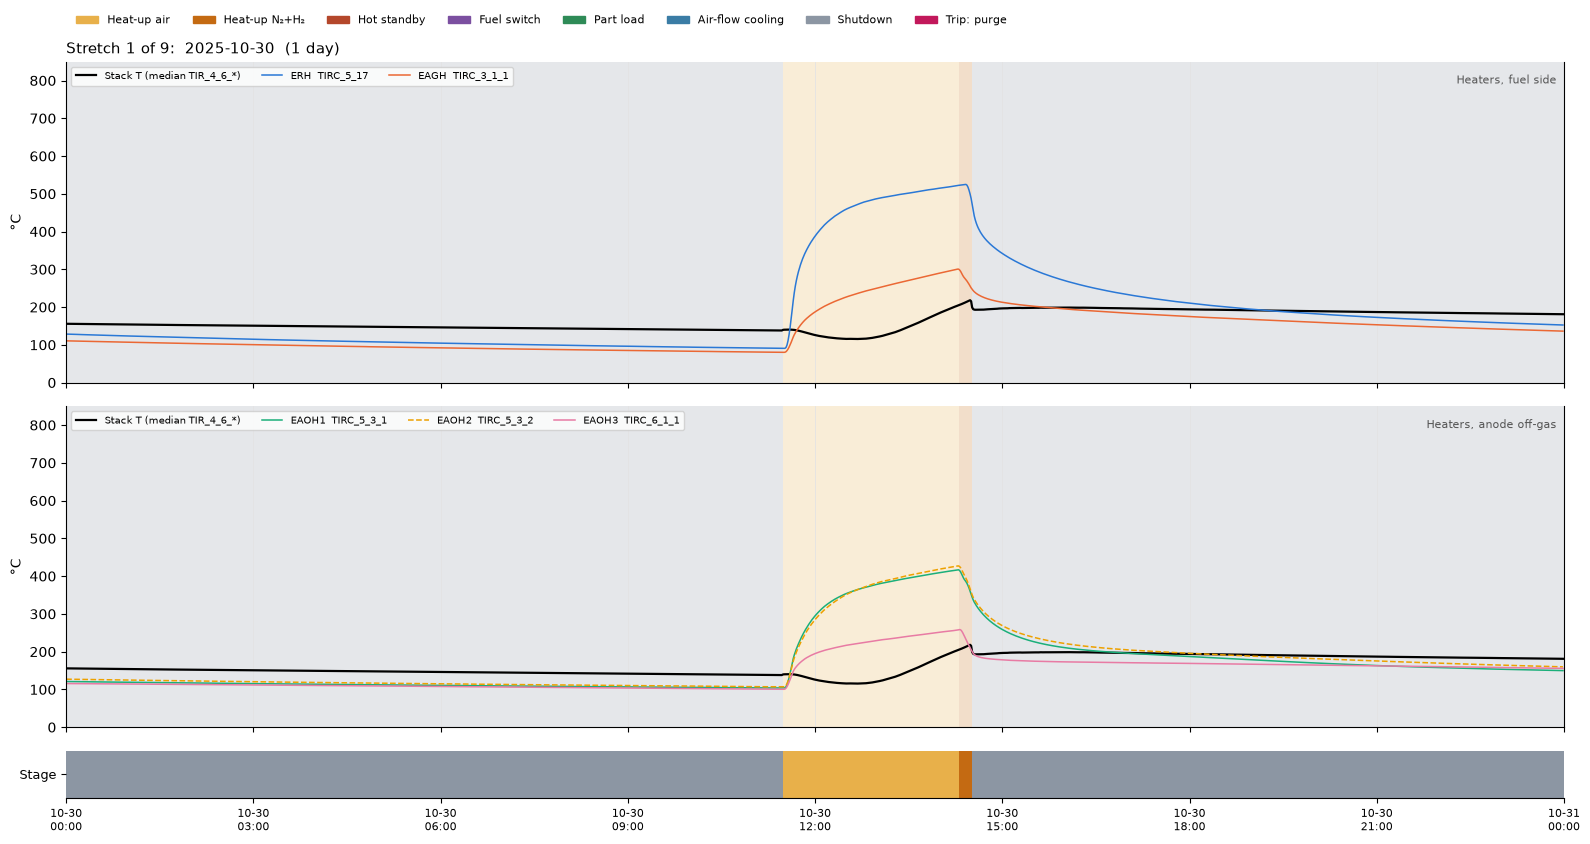

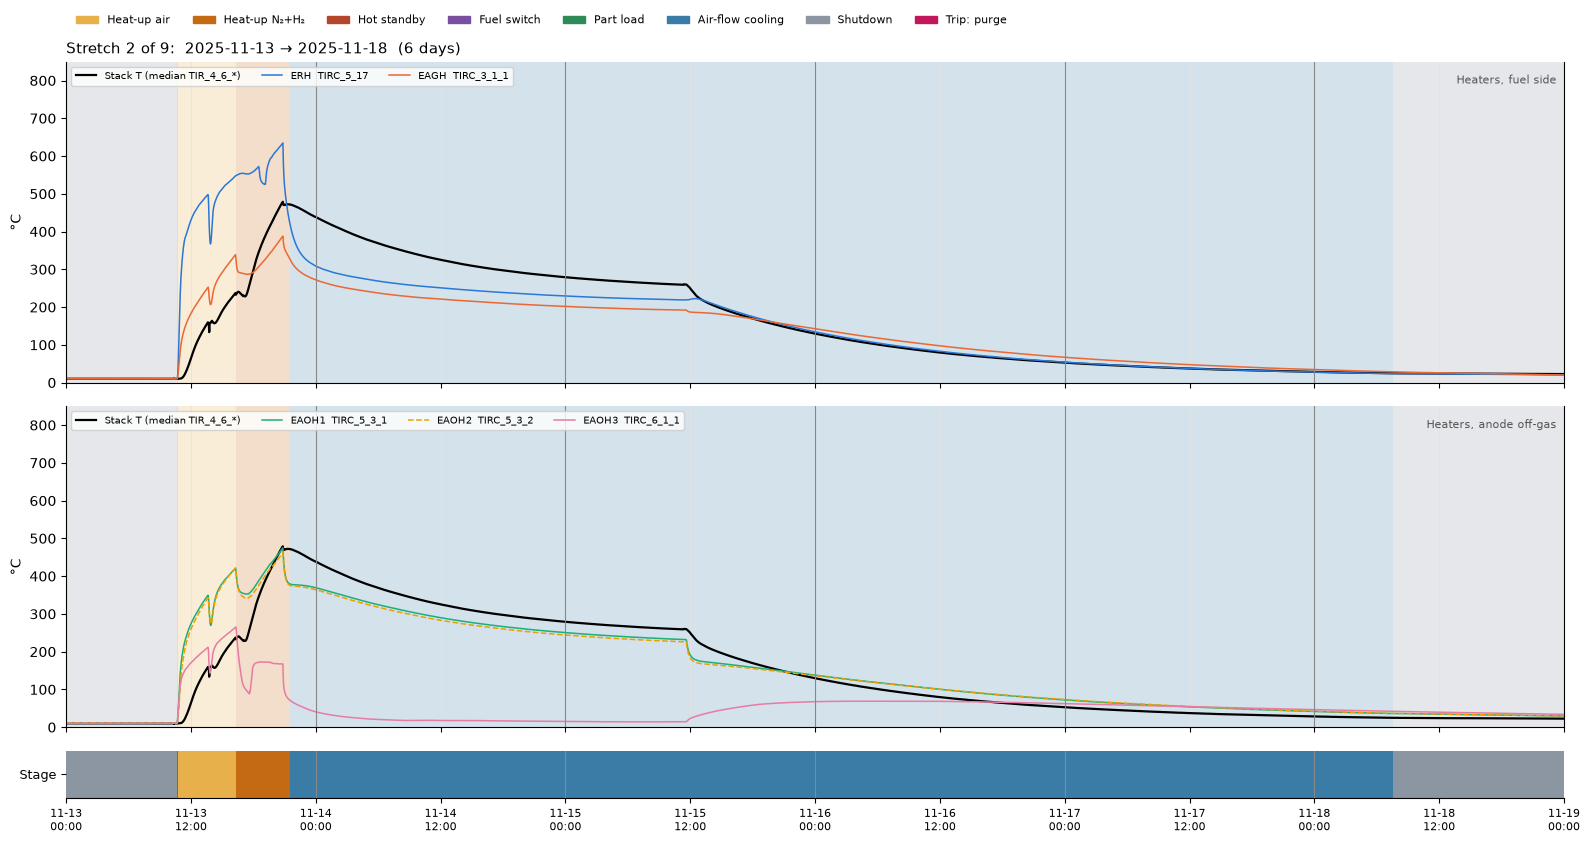

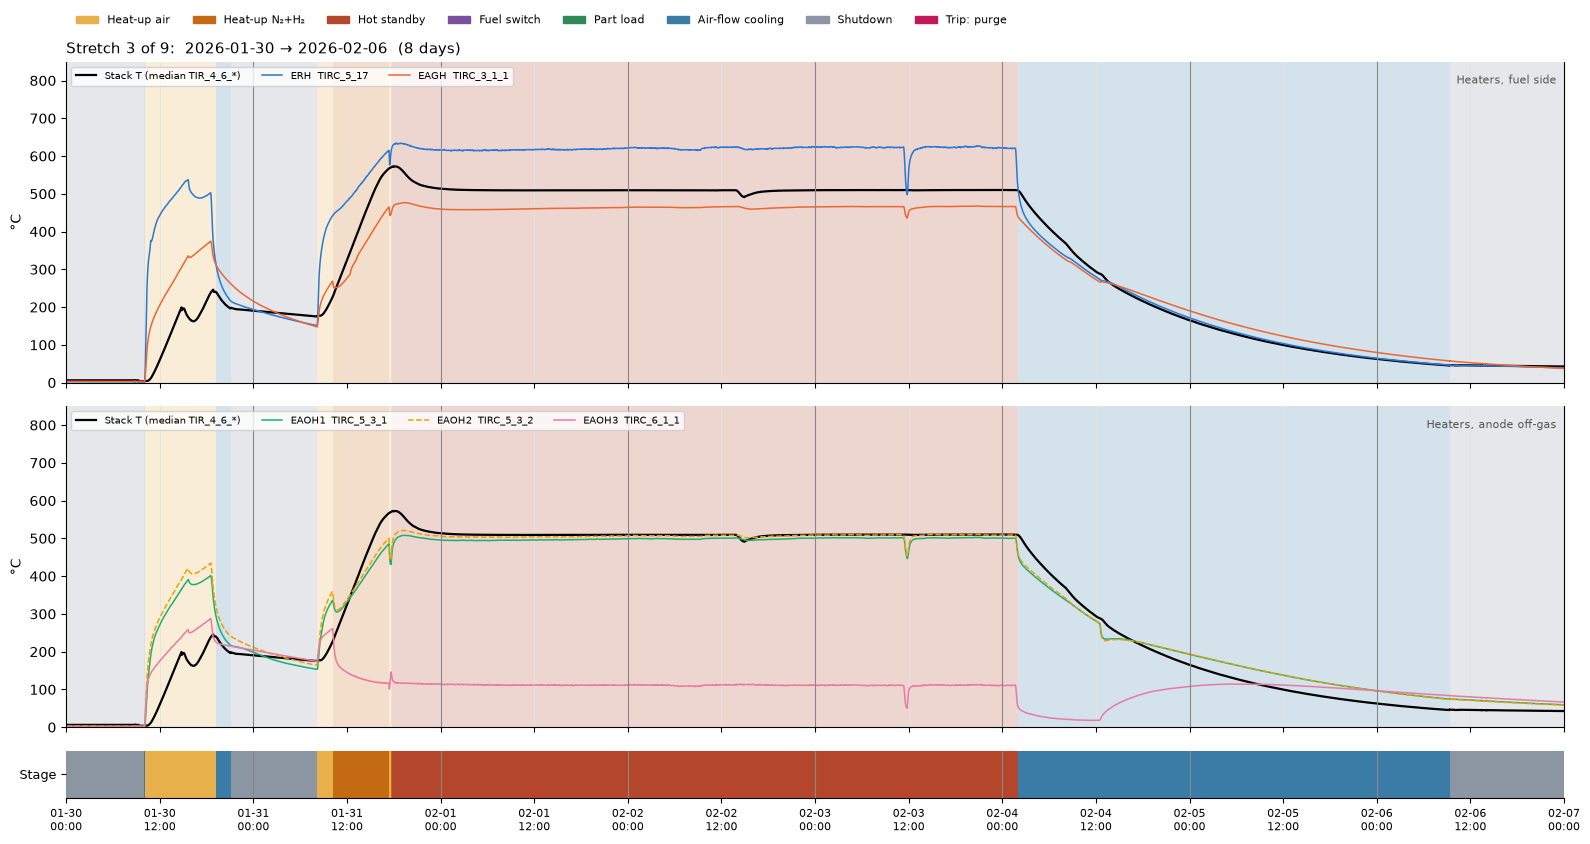

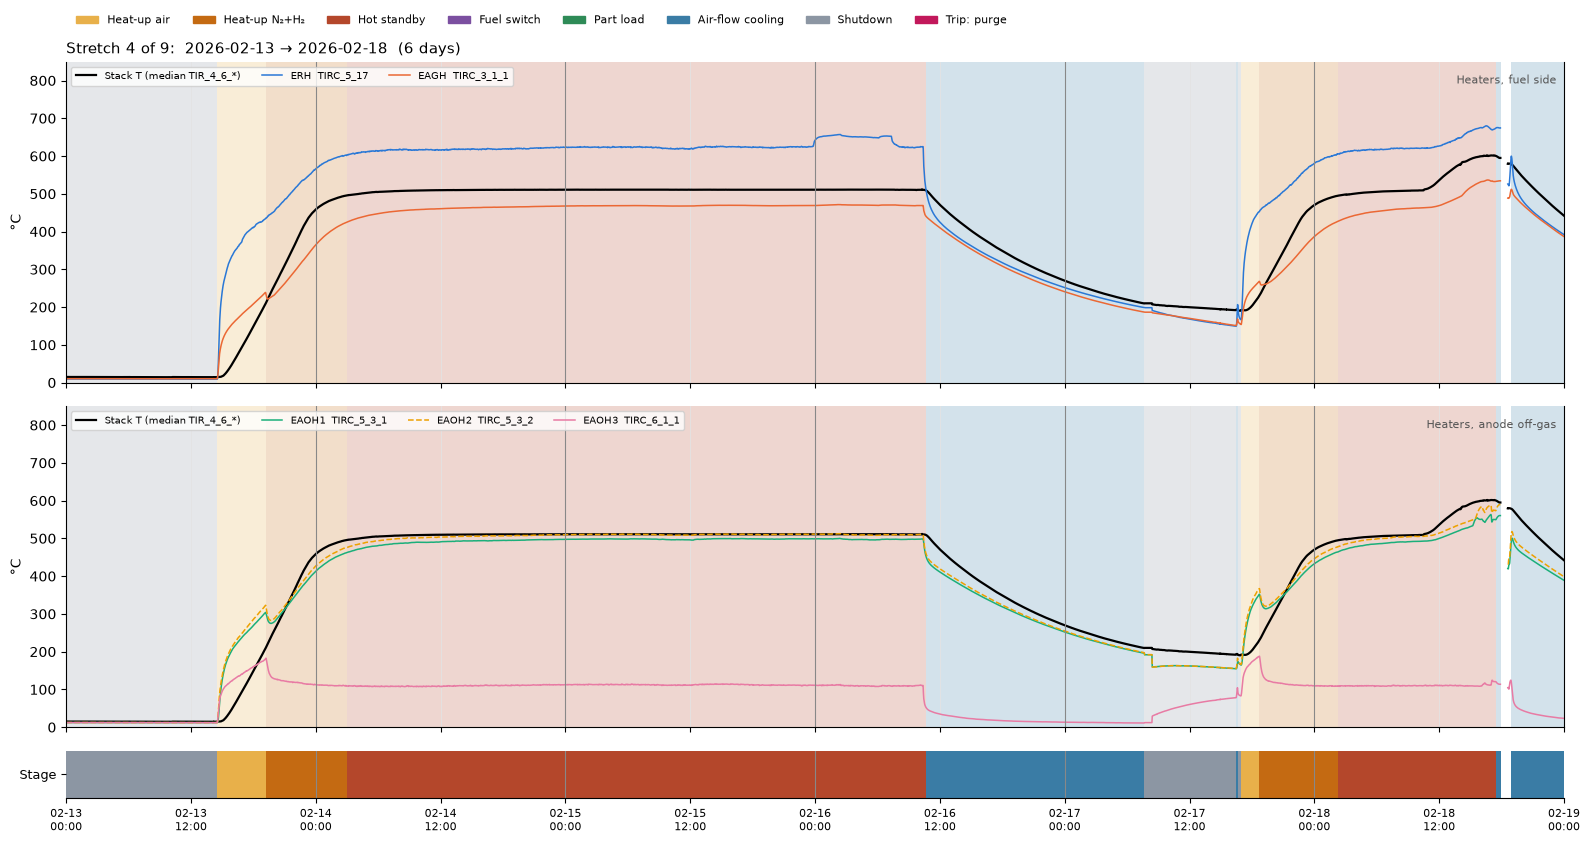

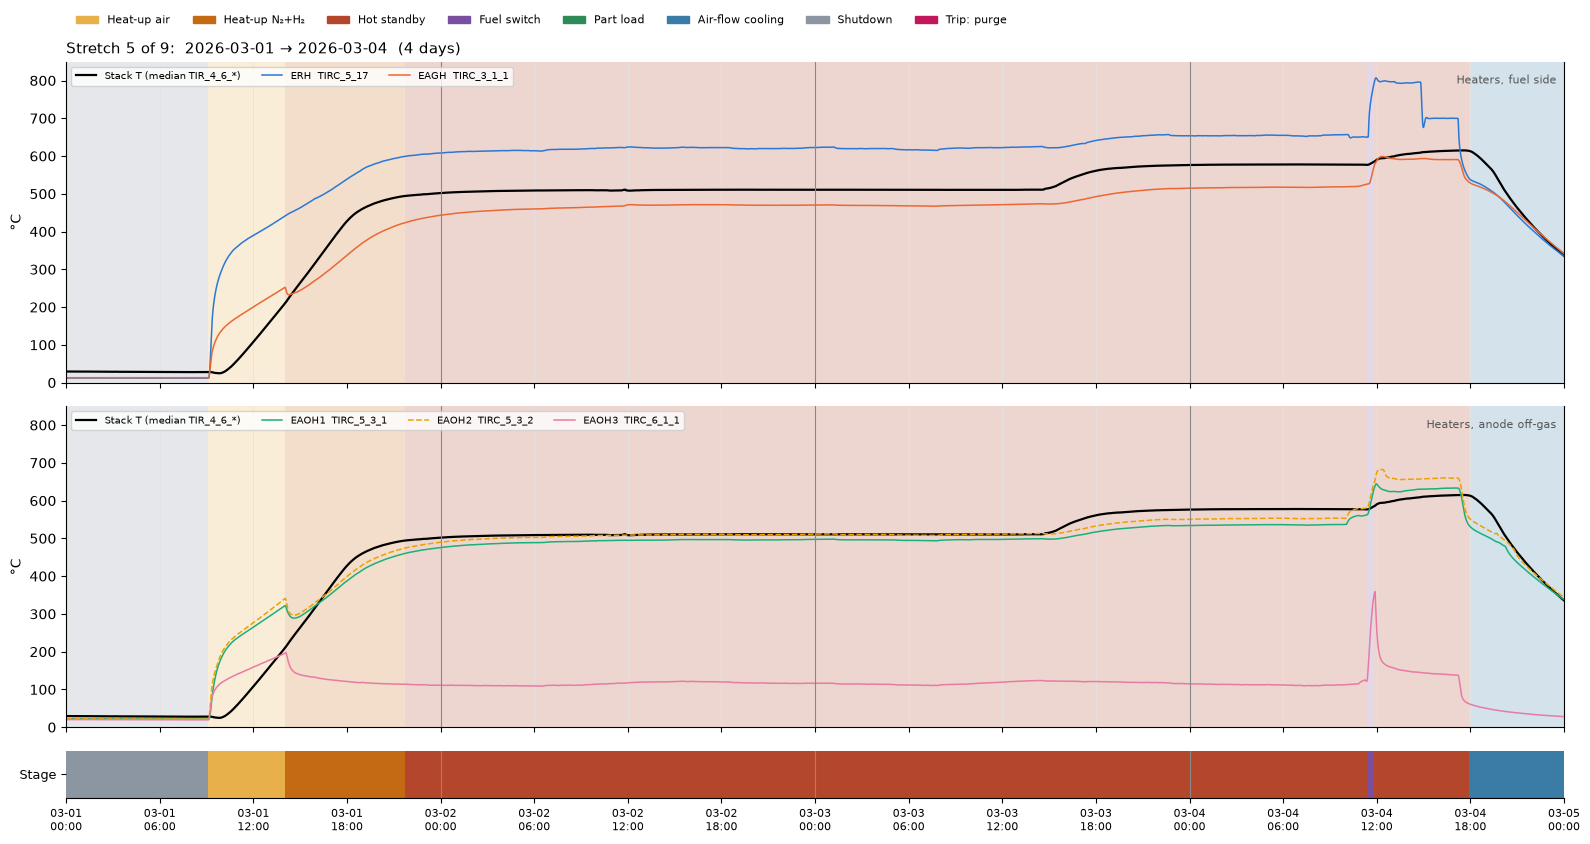

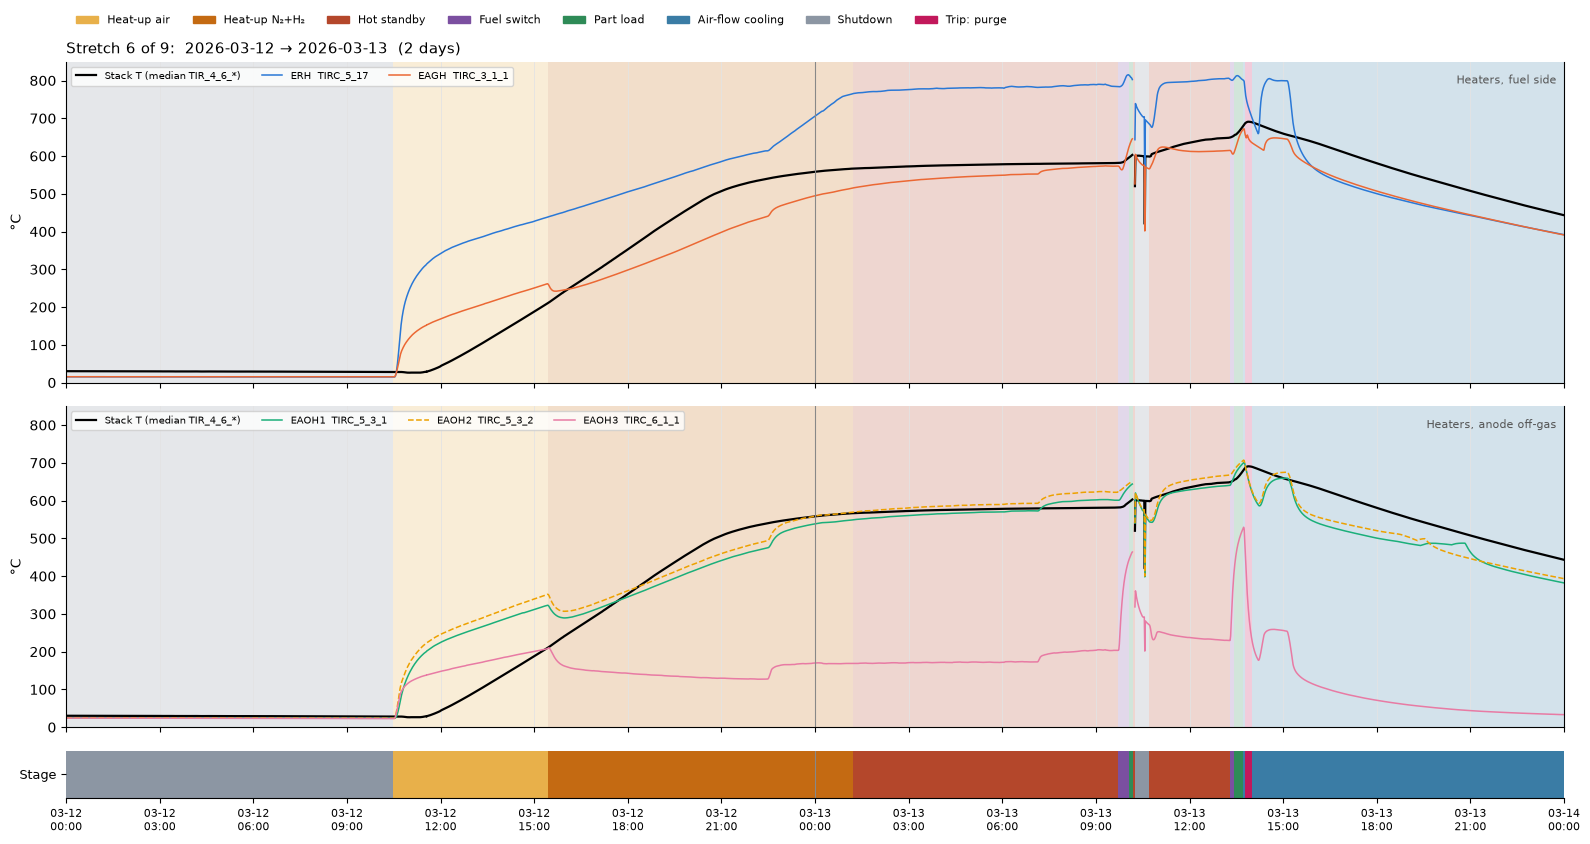

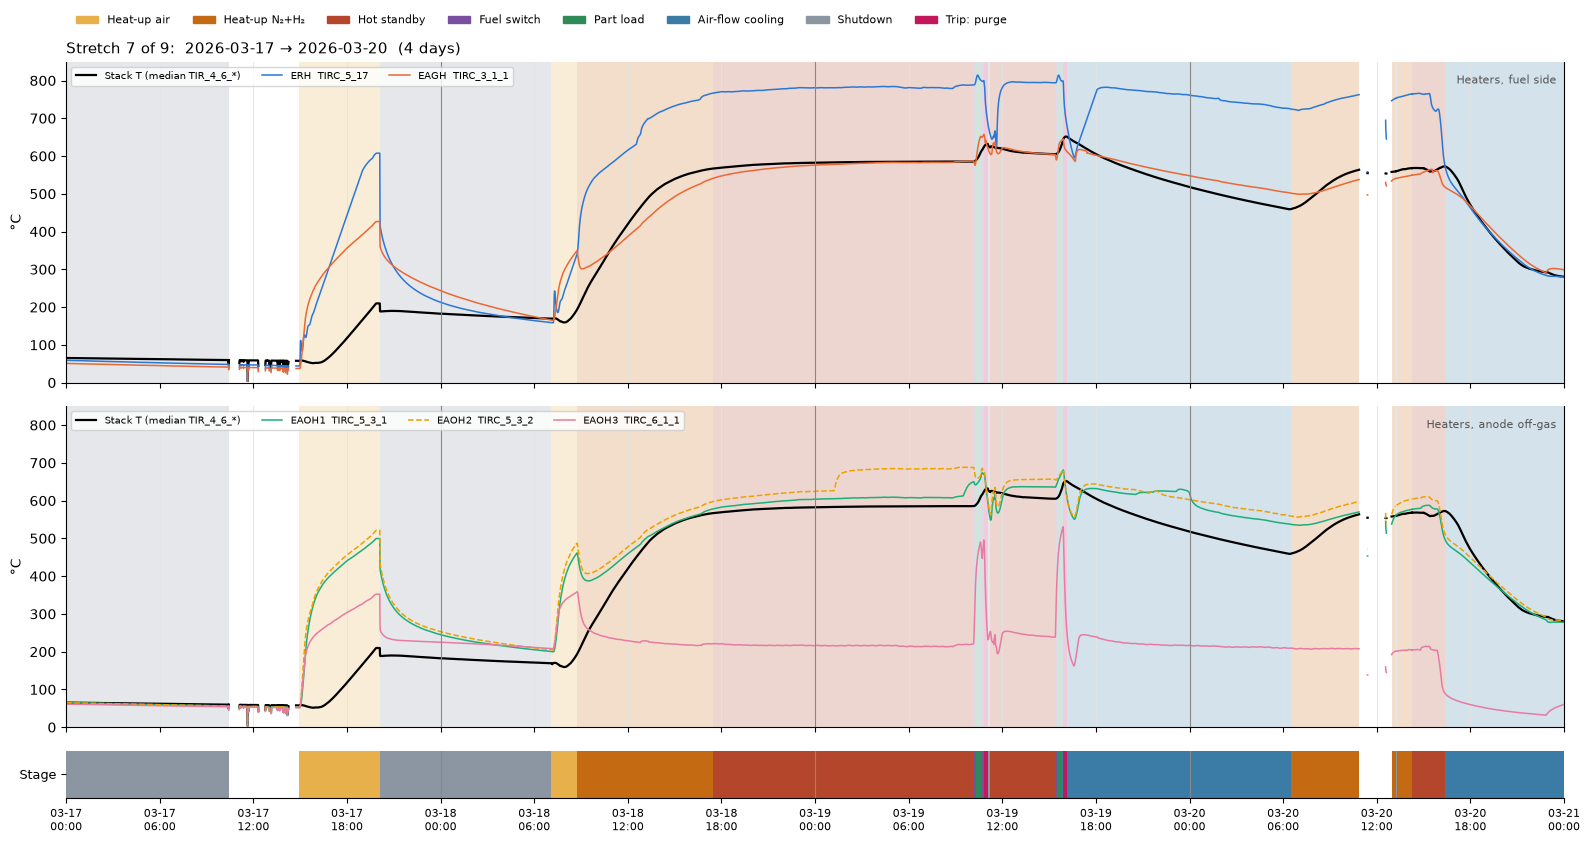

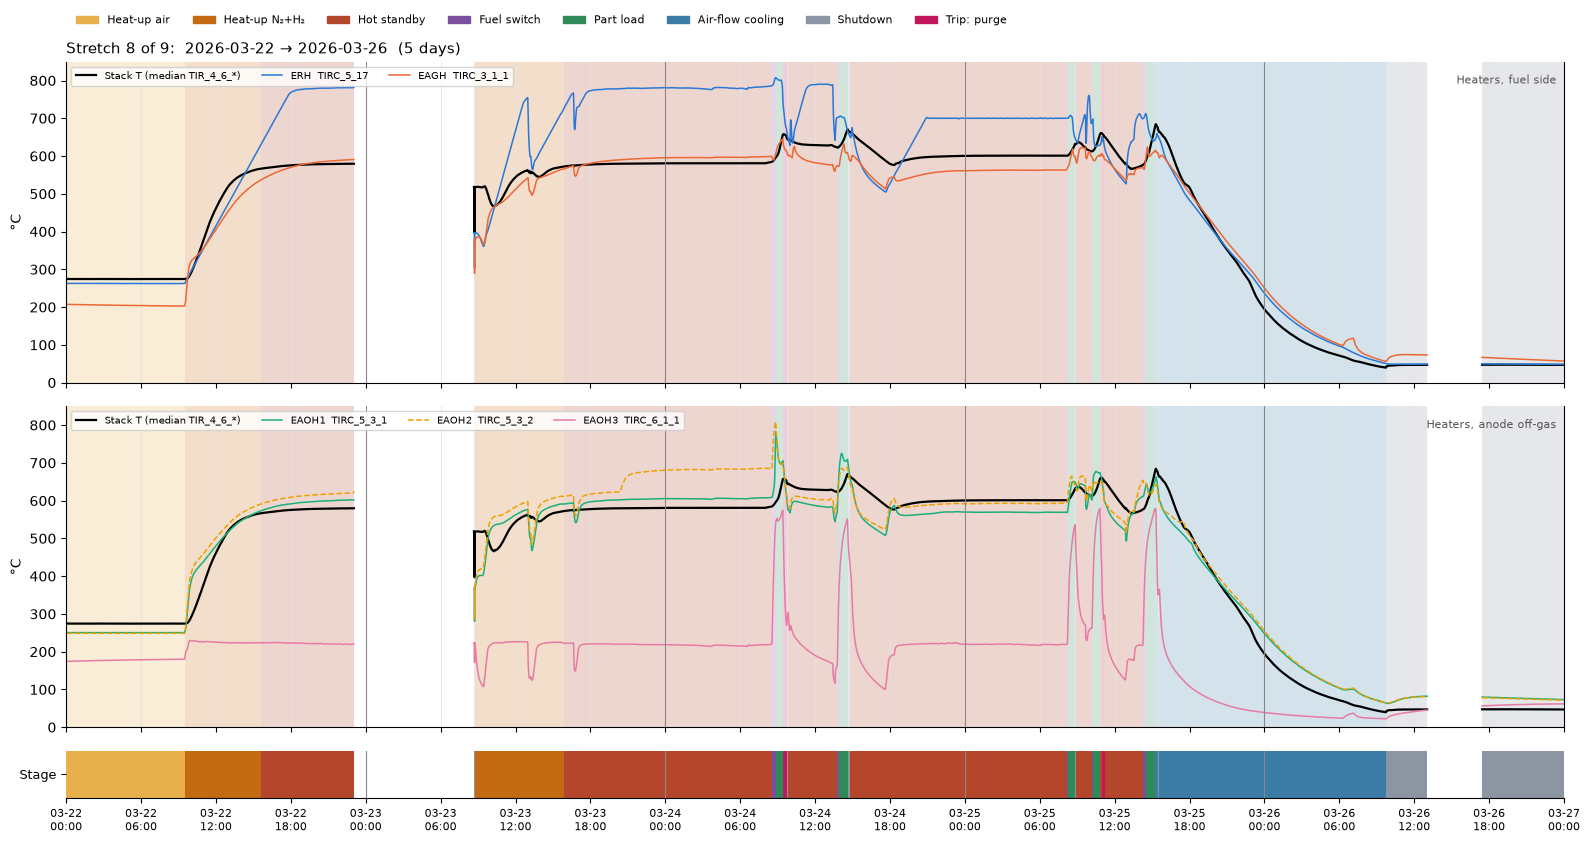

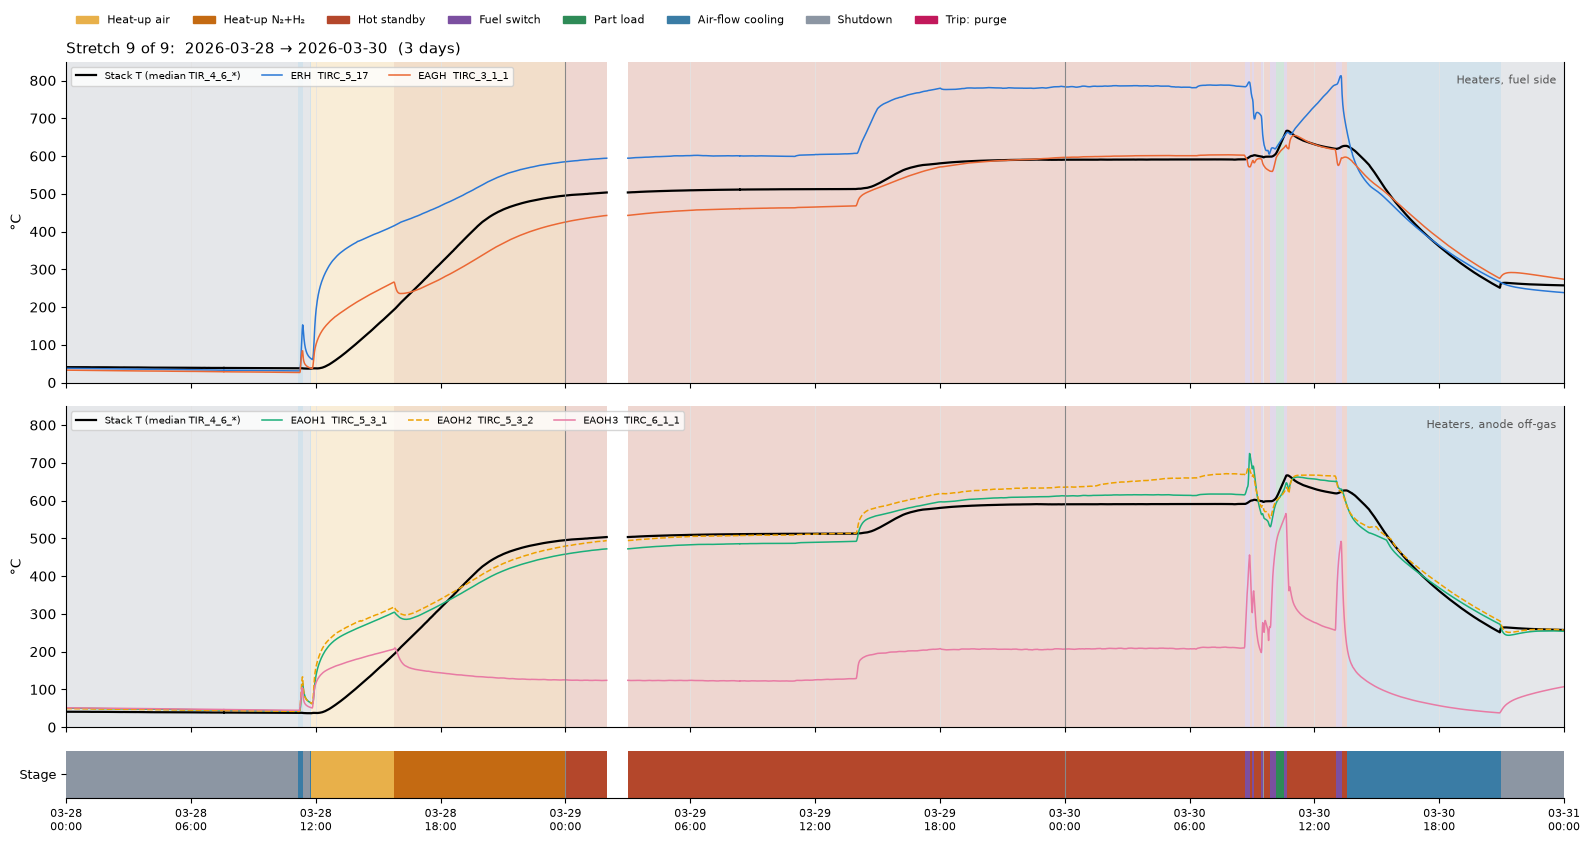

In [4]:
ht.OUT.mkdir(parents=True, exist_ok=True)
for gi, grp in enumerate(groups, 1):
    ht.plot_stretch(
        gi, len(groups), grp, hs, segs, path=ht.OUT / f"stretch_{gi}_{grp[0]}.png"
    )
    plt.show()

## 4. Heaters against the stack, per stage (all day files)

Medians over every labelled minute of the 39 day files (`No data` left out). The heater statistics in 4.1 and 4.2 use only
minutes where **that heater is on** (current > 0.5 A), so an idle heater cooling with the plant does not pull the median down.

In [5]:
st = allm[allm.stage != "No data"]
order = [x for x in ps.STAGES if x in set(st.stage)]


def on_only(col):
    return pd.DataFrame(
        {
            n: st[st[f"{n}_on"]].groupby("stage")[col.format(n=n)].median()
            for n in ht.HEATERS
        }
    ).reindex(order)


stack = st.groupby("stage").T_stack_C.median().reindex(order).rename("Stack T")

### 4.1 Median temperature (°C), heater on

In [6]:
pd.concat([stack, on_only("T_{n}_C")], axis=1).round(0)

,Stack T,ERH,EAGH,EAOH1,EAOH2,EAOH3
stage,,,,,,
Heat-up air,159.0,398.0,228.0,289.0,306.0,186.0
Heat-up N₂+H₂,463.0,559.0,383.0,433.0,449.0,141.0
Hot standby,511.0,624.0,469.0,500.0,510.0,114.0
Fuel switch,595.0,786.0,587.0,630.0,654.0,340.0
Part load,625.0,702.0,623.0,682.0,680.0,491.0
Air-flow cooling,242.0,756.0,551.0,560.0,581.0,216.0
Shutdown,44.0,42.0,43.0,64.0,63.0,72.0
Trip: purge,654.0,676.0,634.0,636.0,634.0,367.0


### 4.2 Median heater minus stack T (K), heater on: > 0 = heater side hotter than the stack

In [7]:
on_only("dT_{n}_K").round(0).style.format("{:.0f}", na_rep="–").background_gradient(
    cmap="RdBu_r", vmin=-300, vmax=300, axis=None
)

,ERH,EAGH,EAOH1,EAOH2,EAOH3
stage,,,,,
Heat-up air,274,108,165,182,76
Heat-up N₂+H₂,123,-54,-1,16,-304
Hot standby,112,-43,-13,-1,-398
Fuel switch,178,-11,35,55,-255
Part load,75,-1,50,49,-129
Air-flow cooling,230,24,41,47,-313
Shutdown,-2,-1,20,19,28
Trip: purge,22,-37,-22,-25,-292


### 4.3 How closely each heater follows the stack

Correlation of heater T with stack T over all minutes of a stage (all heater states). Close to 1 = the heater
temperature moves with the stack; low or negative = it is set by its own heating or by the gas passing through.

In [8]:
corr = pd.DataFrame(
    {
        n: st.groupby("stage")[[f"T_{n}_C", "T_stack_C"]]
        .corr()
        .xs(f"T_{n}_C", level=1)["T_stack_C"]
        for n in ht.HEATERS
    }
).reindex(order)
corr.round(2).style.format("{:.2f}").background_gradient(
    cmap="Greens", vmin=0, vmax=1, axis=None
)

,ERH,EAGH,EAOH1,EAOH2,EAOH3
stage,,,,,
Heat-up air,0.13,0.45,0.36,0.32,0.32
Heat-up N₂+H₂,0.70,0.92,0.88,0.88,0.12
Hot standby,0.73,0.93,0.90,0.86,0.81
Fuel switch,-0.05,0.61,0.25,-0.02,0.44
Part load,-0.23,0.20,0.31,0.15,0.50
Air-flow cooling,0.94,0.97,0.98,0.98,0.24
Shutdown,0.96,0.96,0.95,0.95,0.81
Trip: purge,0.01,0.23,0.31,0.28,-0.01


### 4.4 Distribution per stage

Box plots of heater minus stack T per stage (heater on, whiskers 5–95 %, no outliers drawn). One panel per heater.

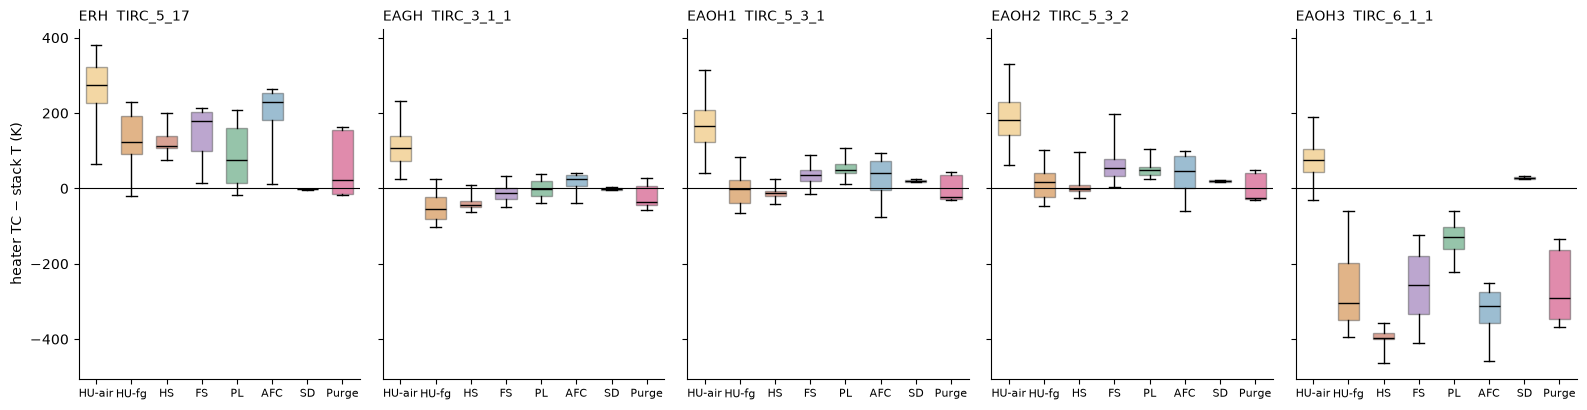

In [9]:
fig, axs = plt.subplots(1, 5, figsize=(16, 4.2), sharey=True)
for a, (n, h) in zip(axs, ht.HEATERS.items()):
    x = st[st[f"{n}_on"]]
    data = [x.loc[x.stage == s_, f"dT_{n}_K"].dropna() for s_ in order]
    bp = a.boxplot(data, whis=(5, 95), showfliers=False, patch_artist=True, widths=0.6)
    for patch, s_ in zip(bp["boxes"], order):
        patch.set(facecolor=ps.COLORS[s_], alpha=0.5, edgecolor="#555")
    for m in bp["medians"]:
        m.set(color="k")
    a.axhline(0, color="k", lw=0.8)
    a.set_xticks(
        range(1, len(order) + 1), [ht.SHORT.get(s_, s_) for s_ in order], fontsize=8
    )
    a.set_title(f"{n}  {h['temp']}", fontsize=10, loc="left")
    a.spines[["top", "right"]].set_visible(False)
axs[0].set_ylabel("heater TC − stack T (K)")
fig.tight_layout()
plt.show()

### 4.5 Distribution of the heater temperatures

How the heater control-TC temperatures (°C) spread within each stage, heater on (current > 0.5 A), so the medians in 4.1
can be read with their range. Minutes are not independent (one run gives hundreds of minutes), so read the shapes, not
the counts.

**4.5.1 Percentiles (°C), heater on.** `n` = minutes with the heater on.

In [10]:
pct = {"P5": 0.05, "P25": 0.25, "P50": 0.5, "P75": 0.75, "P95": 0.95}
rows = {}
for n in ht.HEATERS:
    x = st[st[f"{n}_on"]]
    for s_ in order:
        v = x.loc[x.stage == s_, f"T_{n}_C"].dropna()
        if len(v):
            rows[(n, s_)] = {
                "n": len(v),
                **{k: v.quantile(q) for k, q in pct.items()},
                "max": v.max(),
            }
dist = pd.DataFrame(rows).T.rename_axis(["heater", "stage"])
dist["P95−P5 (K)"] = dist.P95 - dist.P5
dist.round(0).astype({"n": int}).style.format("{:.0f}").background_gradient(
    cmap="Oranges", subset=["P95−P5 (K)"], vmin=0, vmax=400
)

**4.5.2 All stages together, one panel per heater.** Histogram of the heater temperature (heater on, 10 K bins), stacked
by stage in the plant-stage colours; grey outline = stack T over the same minutes; dashed red = trip value of the heater.

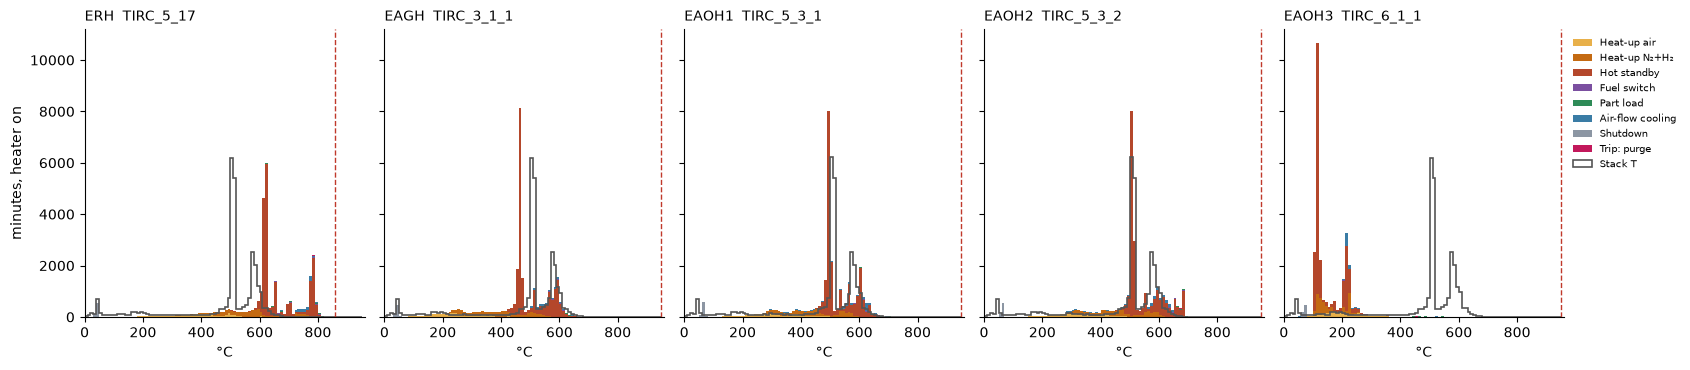

In [11]:
bins = range(0, 960, 10)
fig, axs = plt.subplots(1, 5, figsize=(17, 3.8), sharey=True)
for a, (n, h) in zip(axs, ht.HEATERS.items()):
    x = st[st[f"{n}_on"]]
    a.hist(
        [x.loc[x.stage == s_, f"T_{n}_C"].dropna() for s_ in order],
        bins=bins,
        stacked=True,
        color=[ps.COLORS[s_] for s_ in order],
        label=order,
    )
    a.hist(
        x.T_stack_C.dropna(),
        bins=bins,
        histtype="step",
        color="#555",
        lw=1.2,
        label="Stack T",
    )
    a.axvline(h["trip"], color="#c0392b", ls="--", lw=1)
    a.set_title(f"{n}  {h['temp']}", fontsize=10, loc="left")
    a.set_xlabel("°C")
    a.set_xlim(0, 960)
    a.spines[["top", "right"]].set_visible(False)
axs[0].set_ylabel("minutes, heater on")
axs[-1].legend(fontsize=7, frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
fig.tight_layout()
fig.savefig(ht.OUT / "heater_T_distribution_all.png", dpi=120)
plt.show()

**4.5.3 Per heater and stage.** Rows = heaters, columns = stages; each cell is scaled to its own height (share of that
cell's minutes), so stages with few on-minutes are still readable. Filled = heater T, grey outline = stack T in the same
minutes, black tick = heater median, `n` = minutes. Empty cell = heater never on in that stage.

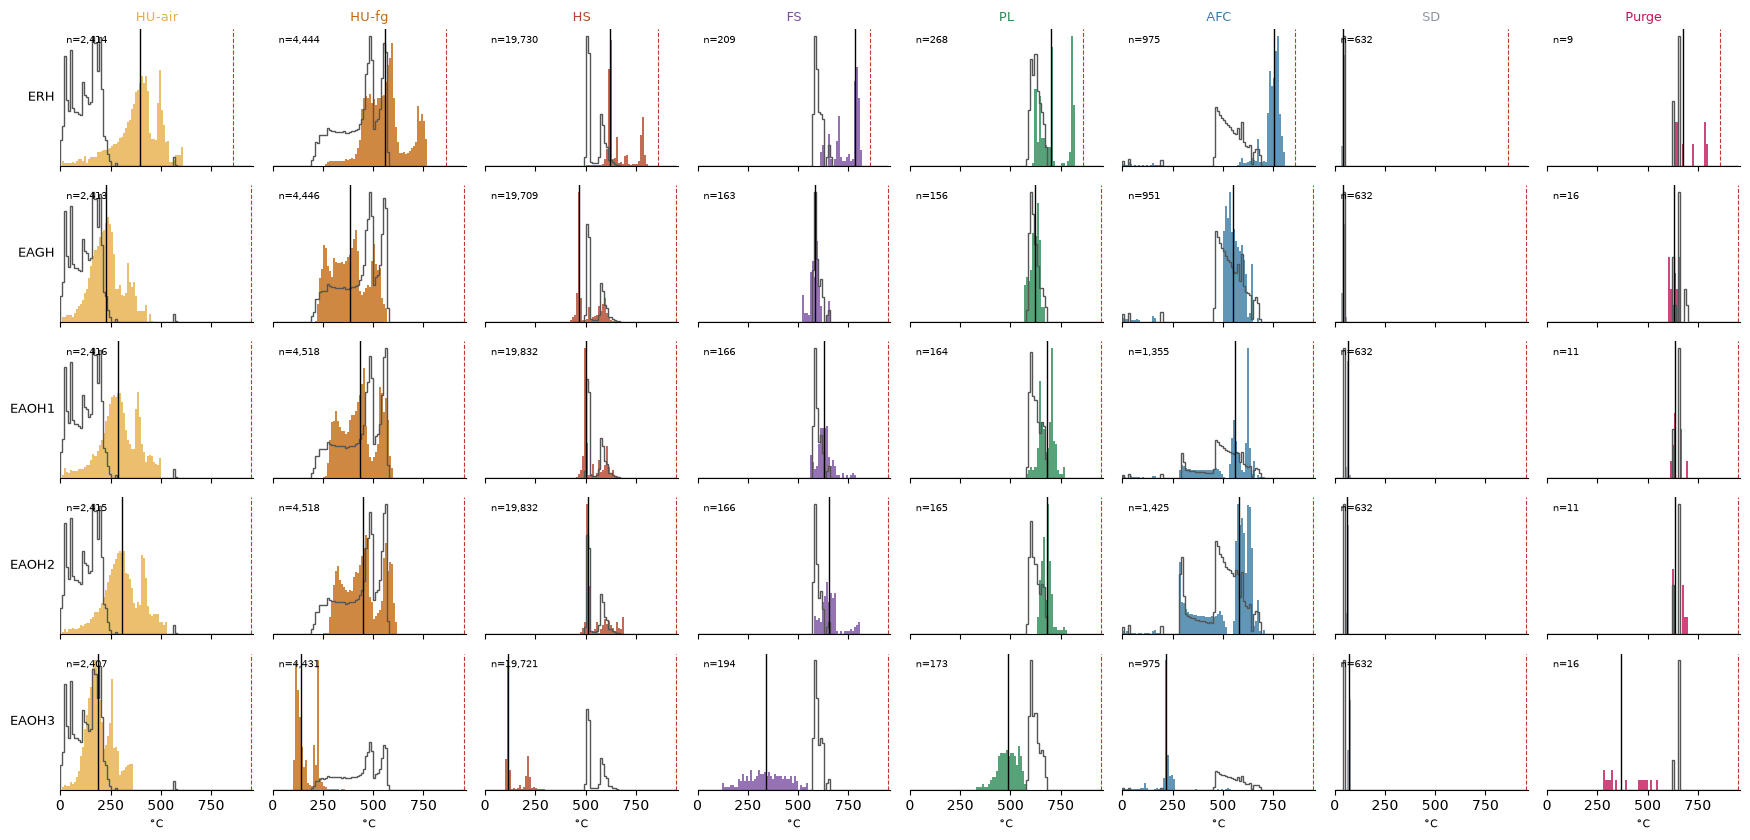

In [12]:
fig, axs = plt.subplots(
    len(ht.HEATERS),
    len(order),
    figsize=(2.2 * len(order), 1.7 * len(ht.HEATERS)),
    sharex=True,
    sharey=False,
)
for i, (n, h) in enumerate(ht.HEATERS.items()):
    x = st[st[f"{n}_on"]]
    for j, s_ in enumerate(order):
        a = axs[i, j]
        v = x.loc[x.stage == s_, f"T_{n}_C"].dropna()
        if len(v):
            a.hist(v, bins=bins, density=True, color=ps.COLORS[s_], alpha=0.8)
            a.hist(
                x.loc[x.stage == s_, "T_stack_C"].dropna(),
                bins=bins,
                density=True,
                histtype="step",
                color="#555",
            )
            a.axvline(v.median(), color="k", lw=1)
            a.text(0.03, 0.9, f"n={len(v):,}", transform=a.transAxes, fontsize=7)
        a.axvline(h["trip"], color="#c0392b", ls="--", lw=0.8)
        a.set_yticks([])
        a.spines[["top", "right", "left"]].set_visible(False)
        if i == 0:
            a.set_title(ht.SHORT.get(s_, s_), fontsize=9, color=ps.COLORS[s_])
        if j == 0:
            a.set_ylabel(n, fontsize=9, rotation=0, ha="right", va="center")
axs[0, 0].set_xlim(0, 960)
for a in axs[-1]:
    a.set_xlabel("°C", fontsize=8)
fig.tight_layout()
fig.savefig(ht.OUT / "heater_T_distribution_by_stage.png", dpi=120)
plt.show()

**4.5.4 Heater minus stack T as histograms (K), heater on.** Same grid, the gap of 4.2 / 4.4 shown as full distributions
(10 K bins, each cell scaled to its own height); black line = 0, i.e. heater as hot as the stack. Two humps in one cell = two kinds of runs in the same stage
(e.g. Hot standby held at ~510 °C vs ~600 °C).

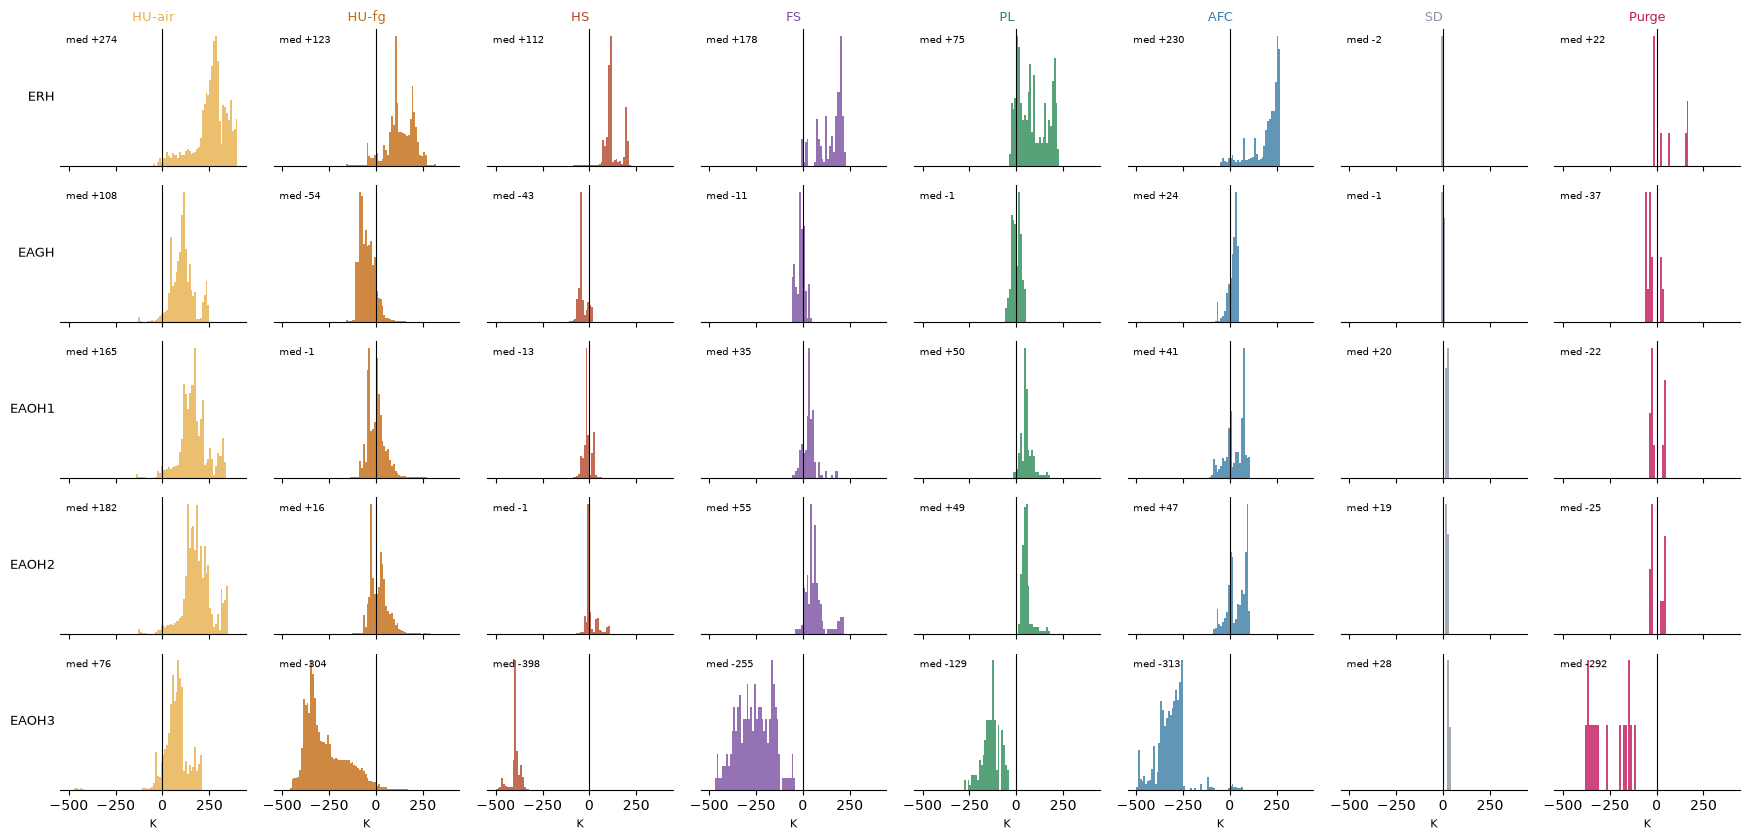

In [13]:
gbins = range(-500, 410, 10)
fig, axs = plt.subplots(
    len(ht.HEATERS),
    len(order),
    figsize=(2.2 * len(order), 1.7 * len(ht.HEATERS)),
    sharex=True,
    sharey=False,
)
for i, n in enumerate(ht.HEATERS):
    x = st[st[f"{n}_on"]]
    for j, s_ in enumerate(order):
        a = axs[i, j]
        v = x.loc[x.stage == s_, f"dT_{n}_K"].dropna()
        if len(v):
            a.hist(v, bins=gbins, density=True, color=ps.COLORS[s_], alpha=0.8)
            a.text(
                0.03, 0.9, f"med {v.median():+.0f}", transform=a.transAxes, fontsize=7
            )
        a.axvline(0, color="k", lw=0.8)
        a.set_yticks([])
        a.spines[["top", "right", "left"]].set_visible(False)
        if i == 0:
            a.set_title(ht.SHORT.get(s_, s_), fontsize=9, color=ps.COLORS[s_])
        if j == 0:
            a.set_ylabel(n, fontsize=9, rotation=0, ha="right", va="center")
for a in axs[-1]:
    a.set_xlabel("K", fontsize=8)
fig.tight_layout()
fig.savefig(ht.OUT / "heater_gap_distribution_by_stage.png", dpi=120)
plt.show()
dist.to_csv(ht.OUT / "heater_T_percentiles.csv", float_format="%.2f")

## 5. Safety thermocouples against the trip values

Highest safety-TC reading per stage (°C) and margin to the trip value (`trip − max`). Same limits as
`operating_states.ipynb` §11.

In [14]:
mx = pd.DataFrame(
    {n: st.groupby("stage")[f"Tsafe_{n}_C"].max() for n in ht.HEATERS}
).reindex(order)
margin = pd.DataFrame({n: h["trip"] - mx[n] for n, h in ht.HEATERS.items()})
display(mx.round(0))
margin.round(0).style.format("{:.0f}").background_gradient(
    cmap="RdYlGn", vmin=0, vmax=400, axis=None
)

,ERH,EAGH,EAOH1,EAOH2,EAOH3
stage,,,,,
Heat-up air,634.0,466.0,505.0,525.0,329.0
Heat-up N₂+H₂,787.0,567.0,594.0,614.0,330.0
Hot standby,829.0,659.0,724.0,696.0,533.0
Fuel switch,834.0,661.0,780.0,805.0,532.0
Part load,834.0,673.0,768.0,774.0,545.0
Air-flow cooling,825.0,677.0,704.0,703.0,547.0
Shutdown,778.0,636.0,696.0,678.0,486.0
Trip: purge,806.0,669.0,705.0,699.0,523.0


,ERH,EAGH,EAOH1,EAOH2,EAOH3
stage,,,,,
Heat-up air,226,484,445,425,621
Heat-up N₂+H₂,73,383,356,336,620
Hot standby,31,291,226,254,417
Fuel switch,26,289,170,145,418
Part load,26,277,182,176,405
Air-flow cooling,35,273,246,247,403
Shutdown,82,314,254,272,464
Trip: purge,54,281,245,251,427


## 6. Save results

In [15]:
cols = (
    ["stage", "old_stage", "operation", "T_stack_C"]
    + [
        c
        for n in ht.HEATERS
        for c in (f"T_{n}_C", f"Tsafe_{n}_C", f"dT_{n}_K", f"{n}_on")
    ]
    + list(ht.NEIGHBOURS)
)
allm[cols].to_csv(ht.OUT / "heater_states_1min.csv", float_format="%.2f")
pd.concat(
    {
        "T_median_on": pd.concat([stack, on_only("T_{n}_C")], axis=1),
        "dT_median_on": on_only("dT_{n}_K"),
        "corr_with_stack": corr,
        "safety_max": mx,
        "trip_margin": margin,
    }
).to_csv(ht.OUT / "heater_per_stage.csv", float_format="%.2f")
sorted(p.name for p in ht.OUT.iterdir())

['heater_T_distribution_all.png',
 'heater_T_distribution_by_stage.png',
 'heater_T_percentiles.csv',
 'heater_gap_distribution_by_stage.png',
 'heater_per_stage.csv',
 'heater_states_1min.csv',
 'stretch_1_20251030.png',
 'stretch_2_20251113.png',
 'stretch_3_20260130.png',
 'stretch_4_20260213.png',
 'stretch_5_20260301.png',
 'stretch_6_20260312.png',
 'stretch_7_20260317.png',
 'stretch_8_20260322.png',
 'stretch_9_20260328.png']

## 7. Findings (8 decided plant stages)

* **Heaters are on in the active stages and off when the plant cools or is shut down:** on in 97 % of Hot standby,
  91 % of Heat-up N₂+H₂, 72 % of Heat-up air and all of Fuel switch / Part load (ERH); on in only 6 % of Air-flow cooling
  and Shutdown and 11–20 % of Trip: purge. The on-only medians for those three stages therefore rest on few minutes.
* **ERH runs hottest and closest to its trip.** With the heater on it sits 75–275 K above the stack (median): ~110 K in
  Hot standby, ~180 K in Fuel switch, ~275 K in Heat-up air. The highest safety reading is 834 °C (2026-03-13 10:01,
  **Fuel switch**; this minute was Hot standby in the old stages), **26 K below the 860 °C trip**. The margin is 25–35 K in
  Hot standby, Fuel switch, Part load and Air-flow cooling.
* **EAGH, EAOH1 and EAOH2 track the stack** within ±55 K (median) in every stage except Heat-up air (110–180 K above a still
  cold stack). Correlation 0.86–0.93 in Heat-up N₂+H₂ and Hot standby, 0.95–0.98 in Air-flow cooling and Shutdown.
* **EAOH3 (recycle) stays far below the stack:** ~115–140 °C in Heat-up N₂+H₂ and Hot standby (300–400 K under the stack),
  340 °C in Fuel switch and ~490 °C only in Part load.
* **Once natural gas is on the heaters stop following the stack:** correlation −0.2 to 0.6 in Fuel switch and Part load,
  ~0 to 0.3 in Trip: purge. In Air-flow cooling and Shutdown they cool together with the stack (0.94–0.98, except EAOH3).
* **Spread of the heater temperatures (4.5):** narrowest in Part load and Hot standby for the off-gas heaters
  (P5–P95 70–180 K), widest in the two heat-ups and Air-flow cooling (270–360 K). **Hot standby is two-humped** for
  ERH (~620 vs ~780 °C), EAGH (~460 vs ~600 °C) and EAOH3 (~110 vs ~215 °C): two kinds of runs share the stage (held
  at ~510 °C vs ~600 °C stack). In **Air-flow cooling ERH stays at 740–800 °C** (230 K above the stack) while the
  others cool with the plant. Highest control-TC reading 815 °C (ERH, Fuel switch / Part load).
* **Shutdown "on" minutes are suspicious:** all five heaters show current > 0.5 A for the same 632 minutes at
  40–70 °C (P5–P95 within 12 K), i.e. a cold plant with heater current; check whether these are heater tests or a
  current-signal offset before using them.
* **Caveat:** on 2026-03-22 the stack T is frozen at 274 °C for ~9.5 h (stretch 8), so the heater-minus-stack values that morning
  are not real.
